# Lab01 — sprint 1

## Лабораторная работа по статистике: физико-химические показатели вина

**Выполнили:**

- Окорокова Елизавета Вадимовна — ИСУ: 504843, ИнфоХимия
- Иванец Никита Вячеславович — ИСУ: 505396, Дизайн

**Тема:** статистический анализ физико-химических показателей красного и белого вина.


In [ ]:
import sys, io, json, base64, zipfile, hashlib, platform, time
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 504843
ALPHA = 0.05
def rng_for(offset=0):
    return np.random.Generator(np.random.PCG64(SEED + offset))
pd.set_option('display.max_rows', 80)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.6g}')
plt.rcParams.update({'figure.dpi': 110, 'font.family': 'DejaVu Sans',
                     'axes.spines.top': False, 'axes.spines.right': False})
COLS = ['pH', 'residual sugar', 'alcohol']
LABELS = {'pH': 'pH', 'residual sugar': 'Остаточный сахар, г/л',
          'alcohol': 'Этанол, % об.'}
COLORS = {'red': '#a13a54', 'white': '#b08a28'}
display(pd.DataFrame({'компонент':['Python','NumPy','pandas','SciPy'],
                      'версия':[platform.python_version(),np.__version__,pd.__version__,scipy.__version__]}))

,компонент,версия
0,Python,3.13.16
1,NumPy,2.1.3
2,pandas,2.2.3
3,SciPy,1.16.3


## Dataset — источник и дизайн исследования

В работе используется **один датасет UCI Wine Quality**, представленный двумя файлами: для красного и белого вина. Это две части одного исследования, а не два независимых датасета.

- **Источник:** [UCI Machine Learning Repository — Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality)
- **Объект исследования:** образцы красного и белого вина.
- **Признаки:** физико-химические измерения, включая pH, остаточный сахар и содержание спирта.


In [ ]:
import pandas as pd
from IPython.display import display

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/'

red = pd.read_csv(url + 'winequality-red.csv', sep=';')
white = pd.read_csv(url + 'winequality-white.csv', sep=';')

red['wine_type'] = 'red'
white['wine_type'] = 'white'

df = pd.concat([red, white], ignore_index=True)

COLS = ['pH', 'residual sugar', 'alcohol']
N = len(df)

audit = pd.DataFrame({
    'Тип вина': ['Красное', 'Белое'],
    'Количество строк': [len(red), len(white)],
    'Пропуски': [
        red.isna().sum().sum(),
        white.isna().sum().sum()
    ],
    'Повторяющиеся строки': [
        red.duplicated().sum(),
        white.duplicated().sum()
    ]
})

display(audit)

display(df[COLS + ['wine_type']].head())

print('Всего образцов:', N)

,Тип вина,Количество строк,Пропуски,Повторяющиеся строки
0,Красное,1599,0,240
1,Белое,4898,0,937


,pH,residual sugar,alcohol,wine_type
0,3.51,1.9,9.4,red
1,3.2,2.6,9.8,red
2,3.26,2.3,9.8,red
3,3.16,1.9,9.8,red
4,3.51,1.9,9.4,red


Всего образцов: 6497


### Разделение данных для анализа

Разделим данные полученные для двух видов вин на две части, примерно 80% будут использованы для подбора распределений и генерации, остальные 20% для проверки полученных данных.

Если данные совпадают, то переписываем их в одну часть. В наборе не указаны партии вина, поэтому мы не можем проверить, связаны ли между собой отдельные образцы из одной партии.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

TRAIN_SHARE = 0.80

group_id = df.groupby(list(df.columns), sort=False).ngroup()
is_train = np.zeros(len(df), dtype=bool)

r_split = rng_for(1)
for wt in ['red', 'white']:
    mask = df['wine_type'].eq(wt)
    gid = group_id[mask]
    sizes = gid.value_counts()
    ids = sizes.index.to_numpy().copy()
    r_split.shuffle(ids)
    cum_rows = np.cumsum(sizes.loc[ids].to_numpy())
    train_ids = ids[cum_rows <= TRAIN_SHARE * mask.sum()]
    is_train[mask.to_numpy()] = gid.isin(train_ids).to_numpy()

is_train = pd.Series(is_train, index=df.index, dtype=bool)
train = df[is_train].copy()
holdout = df[~is_train].copy()

overlap = pd.merge(train.drop_duplicates(), holdout.drop_duplicates(), how='inner')
assert len(overlap) == 0, 'Одинаковые строки попали в обе части'
assert len(train) + len(holdout) == N

table = pd.crosstab(
    df['wine_type'],
    pd.Series(
        np.where(is_train, 'Для настройки', 'Для проверки'),
        index=df.index
    )
)

table = table.rename(index={
    'red': 'Красное',
    'white': 'Белое'
})

table.index.name = 'Тип вина'
table.columns.name = None

display(table)
print('Доля строк для настройки: %.3f' % is_train.mean())


,Для настройки,Для проверки
Тип вина,,
Красное,1279,320
Белое,3918,980


Доля строк для настройки: 0.800


### Почему рассматриваемые величины случайны

Пусть в наборе данных есть $N$ образцов вина. Случайно выбираем один из них. Каждый образец имеет одинаковую вероятность выбора:

$$
P(I)=\frac{1}{N},
$$

где $I$ — номер выбранного образца.

Обозначим через $x_i$ значение показателя у образца $i$. Тогда

$$
X=x_I
$$

— случайная величина, значение которой зависит от выбранного образца.

Если значение $v$ встречается у $n_v$ образцов, то

$$
P(X=v)=\frac{n_v}{N}.
$$

Поскольку значения показателя у образцов различаются, $\operatorname{Var}(X)>0$. Это означает, что случайная величина не является постоянной.

Мы случайно выбираем вино и смотрим значение показателя. До выбора мы не знаем, какое значение получим. Поэтому выбранное значение pH, остаточного сахара или содержания спирта рассматриваем как случайную величину.

In [ ]:
wine_names = {
    'all': 'Все вина',
    'red': 'Красное вино',
    'white': 'Белое вино'
}

summary = pd.DataFrame({
    'Различных значений': df[COLS].nunique(),
    'Выборочная дисперсия': df[COLS].var()
})

display(summary.rename(index=LABELS))

assert (df[COLS].var() > 0).all()

def describe_var(col):
    rows = []

    groups = [
        ('all', df),
        ('red', df[df['wine_type'] == 'red']),
        ('white', df[df['wine_type'] == 'white'])
    ]

    for wine_type, group in groups:
        x = group[col].to_numpy()

        q1 = np.quantile(x, 0.25)
        q3 = np.quantile(x, 0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = (x < lower) | (x > upper)

        rows.append({
            'Тип вина': wine_names[wine_type],
            'Количество образцов': len(x),
            'Среднее': x.mean(),
            'Стандартное отклонение': x.std(ddof=1),
            'Медиана': np.median(x),
            'Минимум': x.min(),
            'Первый квартиль': q1,
            'Третий квартиль': q3,
            'Максимум': x.max(),
            'Асимметрия': stats.skew(x, bias=False),
            'Эксцесс': stats.kurtosis(x, bias=False),
            'Потенциальные выбросы, %': outliers.mean() * 100
        })

    return pd.DataFrame(rows)

def eda_plot(col):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    for wine_type in ['red', 'white']:
        x = df.loc[df['wine_type'] == wine_type, col].to_numpy()

        ax[0].hist(
            x,
            bins='fd',
            density=True,
            histtype='step',
            linewidth=1.7,
            label=wine_names[wine_type],
            color=COLORS[wine_type]
        )

        sorted_x = np.sort(x)
        fractions = np.arange(1, len(x) + 1) / len(x)

        ax[1].step(
            sorted_x,
            fractions,
            where='post',
            label=wine_names[wine_type],
            color=COLORS[wine_type]
        )

    ax[0].set_title('Распределение значений')
    ax[0].set_xlabel(LABELS[col])
    ax[0].set_ylabel('Плотность')
    ax[0].legend()

    ax[1].set_title('Эмпирическая функция распределения')
    ax[1].set_xlabel(LABELS[col])
    ax[1].set_ylabel('Доля образцов')
    ax[1].legend()

    red_values = df.loc[df['wine_type'] == 'red', col]
    white_values = df.loc[df['wine_type'] == 'white', col]

    ax[2].boxplot([red_values, white_values])
    ax[2].set_xticks([1, 2])
    ax[2].set_xticklabels(['Красное', 'Белое'])
    ax[2].set_title('Ящик с усами')
    ax[2].set_ylabel(LABELS[col])

    plt.tight_layout()
    plt.show()

,Различных значений,Выборочная дисперсия
pH,108,0.0258525
"Остаточный сахар, г/л",316,22.6367
"Этанол, % об.",111,1.42256


## Random Variable 01 — pH

### Description (природа события)

pH характеризует кислотность вина. Чем ниже pH, тем более кислая среда. Значение зависит от состава кислот и других компонентов вина.

В этой работе случайный эксперимент — равновероятно выбрать один образец вина из рассматриваемого набора. Случайная величина $X_1$ — измеренное и записанное в датасете значение pH выбранного образца.

### EDA & Distribution

Исследуем описательные статистики и форму распределения pH отдельно для красного и белого вина. Затем сравним эмпирическое распределение с несколькими теоретическими моделями.


,Тип вина,Количество образцов,Среднее,Стандартное отклонение,Медиана,Минимум,Первый квартиль,Третий квартиль,Максимум,Асимметрия,Эксцесс,"Потенциальные выбросы, %"
0,Все вина,6497,3.2185,0.160787,3.21,2.72,3.11,3.32,4.01,0.386839,0.367657,1.1236
1,Красное вино,1599,3.31111,0.154386,3.31,2.74,3.21,3.4,4.01,0.193683,0.806943,2.18887
2,Белое вино,4898,3.18827,0.151001,3.18,2.72,3.09,3.28,3.82,0.457783,0.530775,1.53124


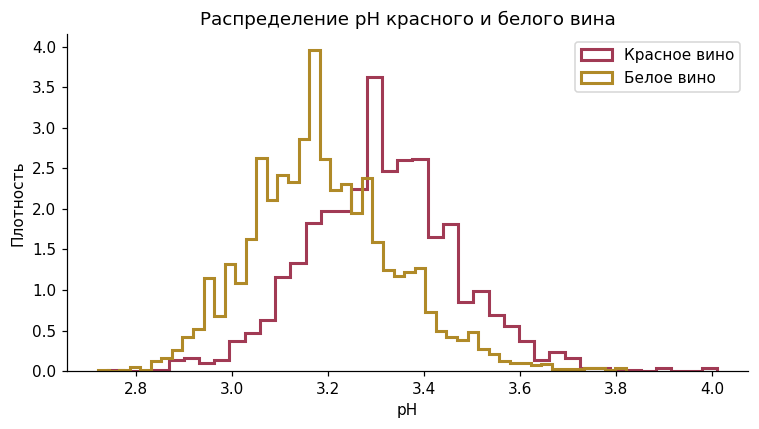

In [ ]:
import matplotlib.pyplot as plt

display(describe_var('pH'))

plt.figure(figsize=(7, 4))

for wine_type, name, color in [
    ('red', 'Красное вино', '#a13a54'),
    ('white', 'Белое вино', '#b08a28')
]:
    values = df.loc[df['wine_type'] == wine_type, 'pH']

    plt.hist(
        values,
        bins='fd',
        density=True,
        histtype='step',
        linewidth=2,
        label=name,
        color=color
    )

plt.title('Распределение pH красного и белого вина')
plt.xlabel('pH')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

### Independence & Estimations

Связи pH с остаточным сахаром и содержанием спирта рассмотрены в общем разделе «Связи внутри пар» ниже, чтобы не дублировать расчёты. Там же исследуется зависимость между признаками. Оценки среднего и дисперсии при увеличении размера выборки рассматриваются в разделе о состоятельности оценок.


## Random Variable 02 — остаточный сахар (г/л)

### Description (природа события)

Остаточный сахар — количество сахаров, оставшихся после брожения, в пересчёте на литр вина. Его значение зависит от исходного состава винограда и условий брожения.

Случайная величина \(X_2\) — значение остаточного сахара в случайно выбранном образце вина.

### EDA & Distribution

Рассчитываем описательные статистики и строим графики распределения отдельно для красного и белого вина.


,Тип вина,Количество образцов,Среднее,Стандартное отклонение,Медиана,Минимум,Первый квартиль,Третий квартиль,Максимум,Асимметрия,Эксцесс,"Потенциальные выбросы, %"
0,Все вина,6497,5.44324,4.7578,3,0.6,1.8,8.1,65.8,1.4354,4.35927,1.81622
1,Красное вино,1599,2.53881,1.40993,2.2,0.9,1.9,2.6,15.5,4.54066,28.6176,9.69356
2,Белое вино,4898,6.39141,5.07206,5.2,0.6,1.7,9.9,65.8,1.07709,3.46982,0.142915


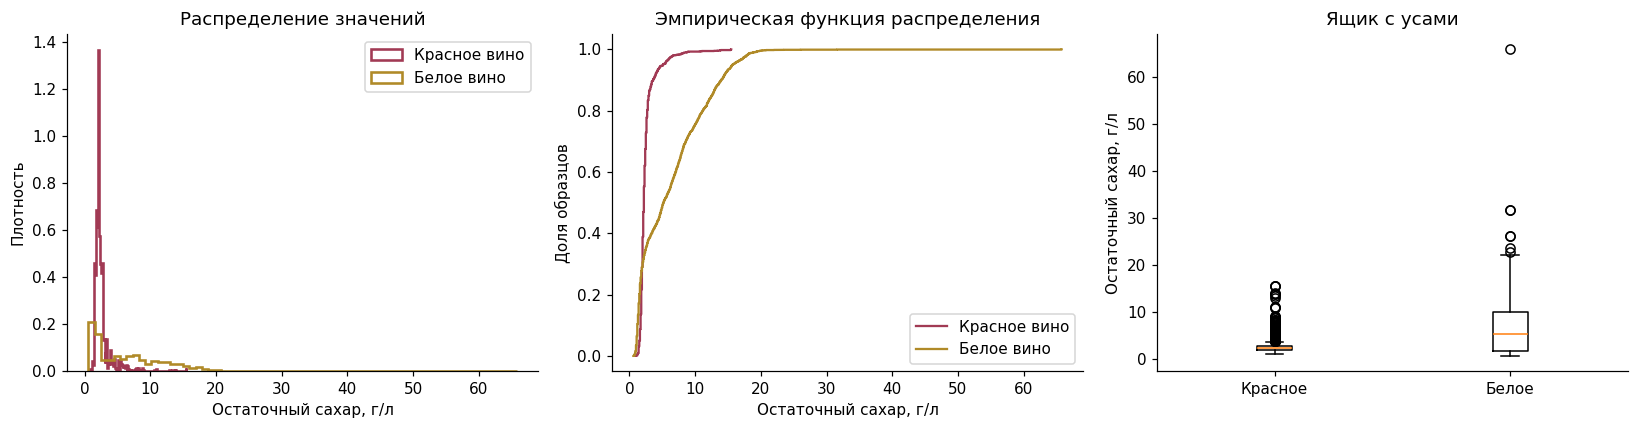

In [ ]:
display(describe_var('residual sugar'))
eda_plot('residual sugar')

## Random Variable 03 — содержание этанола (% об.)

### Description (природа события)

Показатель `alcohol` — объёмная доля этанола в вине, выраженная в процентах. Этанол образуется в процессе брожения сахаров.

Случайная величина \(X_3\) — значение содержания спирта в случайно выбранном образце вина.

### EDA & Distribution

Рассчитываем описательные статистики и строим графики распределения отдельно для красного и белого вина.


,Тип вина,Количество образцов,Среднее,Стандартное отклонение,Медиана,Минимум,Первый квартиль,Третий квартиль,Максимум,Асимметрия,Эксцесс,"Потенциальные выбросы, %"
0,Все вина,6497,10.4918,1.19271,10.3,8,9.5,11.3,14.9,0.565718,-0.531687,0.0461752
1,Красное вино,1599,10.423,1.06567,10.2,8.4,9.5,11.1,14.9,0.860829,0.200029,0.813008
2,Белое вино,4898,10.5143,1.23062,10.4,8,9.5,11.4,14.2,0.487342,-0.698425,0


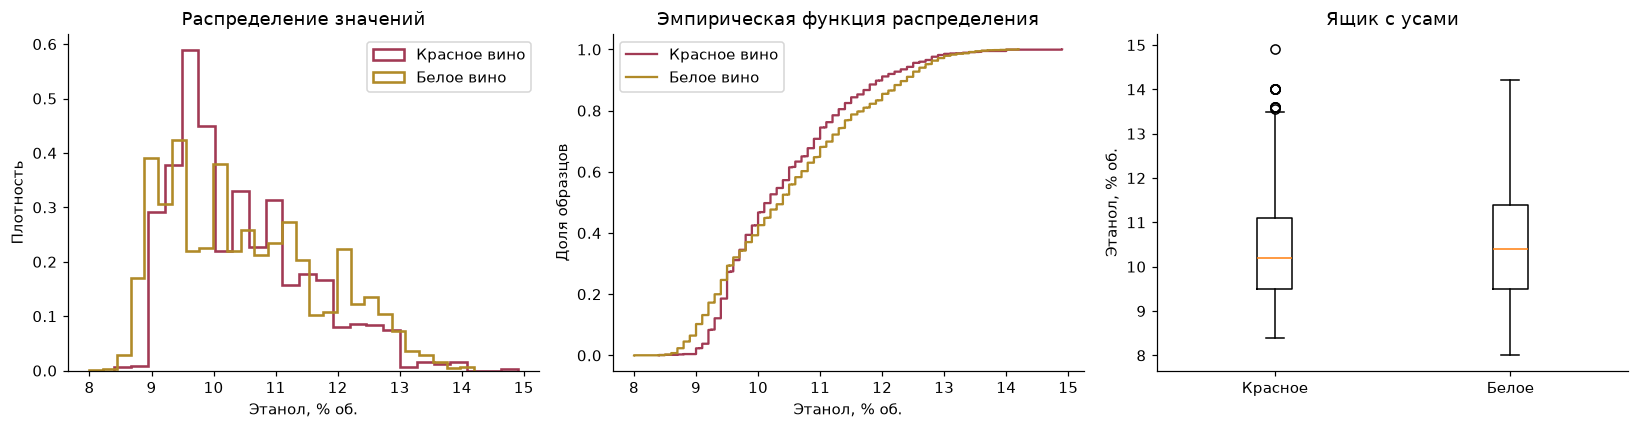

In [ ]:
display(describe_var('alcohol'))
eda_plot('alcohol')

## Математические модели распределений

**Нормальное $N(\mu,\sigma^2)$:**
$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\quad x\in\mathbb R.$$
$E(X)=\mu$, $D(X)=\sigma^2$; симметрия, нулевые асимметрия и эксцесс. MLE: $\hat\mu=\bar x$, $\hat\sigma^2=n^{-1}\sum(x_i-\bar x)^2$. Неограниченная область значений может быть недостатком для химических концентраций.

**Логнормальное $LN(\mu,\sigma^2)$:** $\log X\sim N(\mu,\sigma^2)$,
$$f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\!\left(-\frac{(\log x-\mu)^2}{2\sigma^2}\right),\quad x>0.$$
$E(X)=e^{\mu+\sigma^2/2}$, $D(X)=(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$. В SciPy `shape=σ`, `scale=exp(μ)`, `loc=0`. Удобна для положительных асимметричных данных.

**Гамма $\Gamma(k,\theta)$:**
$$f(x)=\frac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\theta^k},\quad x>0;\qquad E(X)=k\theta,\quad D(X)=k\theta^2.$$
`shape=k`, `scale=θ`, `loc=0`; при $k>1$ одна мода $(k-1)\theta$, асимметрия $2/\sqrt{k}$. Не описывает произвольную многомодальность.

**Эмпирическое распределение** строится по наблюдаемым данным. Его функция показывает, какая доля значений не превышает выбранный уровень $x$:

$$
\hat F_n(x)=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}(x_i\leq x).
$$

Здесь $n$ — количество наблюдений. Каждое значение, не превышающее $x$, добавляет к сумме единицу.

Вероятность каждого наблюдаемого значения определяется тем, как часто оно встречается в данных. Такое распределение удобно для округлённых измерений. Оно сохраняет наблюдаемые значения, но не позволяет моделировать значения за пределами их диапазона.

Для pH рассматриваем нормальное распределение. Для сахара и этанола сравниваем три варианта: нормальное, логнормальное и гамма-распределение.

Параметры моделей подбираем отдельно для красного и белого вина. Для этого используем данные, выделенные для настройки. Затем проверяем модели на оставленной части данных.

Для сравнения используем два показателя:

- BIC — учитывает качество подгонки и количество параметров модели.
- Средняя отрицательная логарифмическая плотность — оценивает, насколько хорошо модель описывает проверочные данные.

Меньшие значения этих показателей считаем предпочтительными. Однако даже лучшая из проверенных моделей может недостаточно хорошо описывать данные.

Измерения в таблице округлены, поэтому расчёты по плотности являются приближёнными. Более точный расчёт должен учитывать интервал округления каждого значения.

,Тип вина,Показатель,Распределение,Параметры распределения,Критерий BIC на данных для настройки,Средняя отрицательная логарифмическая плотность на проверке,Расстояние Колмогорова на проверке
5,Красное вино,"Этанол, % об.",Логнормальное,"(0.098922, 0.0, 10.366379)",3708.27,1.4437,0.121225
6,Красное вино,"Этанол, % об.",Гамма,"(100.279084, 0.0, 0.103893)",3736.68,1.45665,0.122929
4,Красное вино,"Этанол, % об.",Нормальное,"(10.418283, 1.064142)",3802.98,1.48676,0.125635
12,Белое вино,"Этанол, % об.",Логнормальное,"(0.115367, 0.0, 10.451962)",12601.9,1.58749,0.0871626
13,Белое вино,"Этанол, % об.",Гамма,"(74.501747, 0.0, 0.141238)",12652.5,1.59421,0.0894344
11,Белое вино,"Этанол, % об.",Нормальное,"(10.522501, 1.234926)",12788.8,1.61216,0.0932234
0,Красное вино,pH,Нормальное,"(3.311525, 0.156672)",-1097.56,-0.508528,0.0686003
7,Белое вино,pH,Нормальное,"(3.18794, 0.150403)",-3709.47,-0.456097,0.0440955
2,Красное вино,"Остаточный сахар, г/л",Логнормальное,"(0.359743, 0.0, 2.338752)",3202.07,1.21588,0.171742
3,Красное вино,"Остаточный сахар, г/л",Гамма,"(6.167788, 0.0, 0.412107)",3559.34,1.33381,0.211803


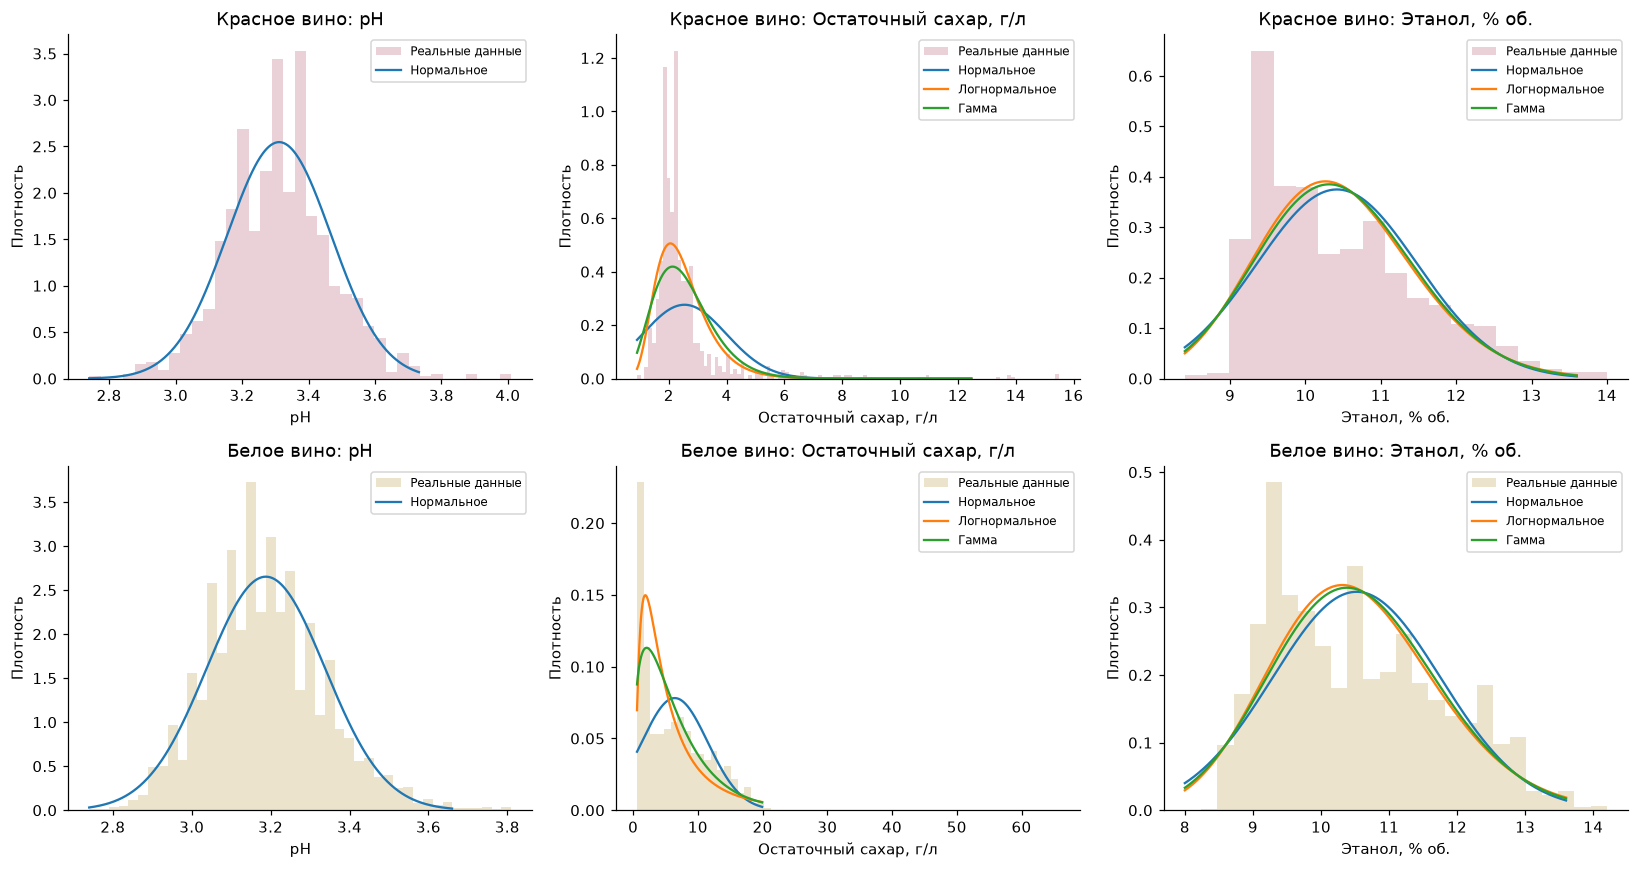

In [ ]:
wine_labels = {
    'red': 'Красное вино',
    'white': 'Белое вино'
}

distribution_labels = {
    'normal': 'Нормальное',
    'lognormal': 'Логнормальное',
    'gamma': 'Гамма'
}

fits = {}
fit_rows = []

for color in ['red', 'white']:
    for col in COLS:

        x = train.loc[train['wine_type'] == color, col].to_numpy()
        y = holdout.loc[holdout['wine_type'] == color, col].to_numpy()

        if col == 'pH':
            candidates = {
                'normal': stats.norm
            }
        else:
            candidates = {
                'normal': stats.norm,
                'lognormal': stats.lognorm,
                'gamma': stats.gamma
            }

        for name, dist in candidates.items():

            if name == 'normal':
                pars = dist.fit(x)
            else:
                pars = dist.fit(x, floc=0)

            model = dist(*pars)
            fits[(color, col, name)] = model

            k = 2

            fit_rows.append({
                'тип': color,
                'величина': col,
                'модель': name,
                'параметры SciPy': str(
                    tuple(float(round(v, 6)) for v in pars)
                ),
                'BIC_train': (
                    k * np.log(len(x))
                    - 2 * model.logpdf(x).sum()
                ),
                'NLL_holdout': -model.logpdf(y).mean(),
                'KS_D_holdout': stats.kstest(
                    y, model.cdf
                ).statistic
            })
fit_table = pd.DataFrame(fit_rows)

display_table = (
    fit_table
    .sort_values(['величина', 'тип', 'NLL_holdout'])
    .replace({
        'тип': wine_labels,
        'величина': LABELS,
        'модель': distribution_labels
    })
    .rename(columns={
        'тип': 'Тип вина',
        'величина': 'Показатель',
        'модель': 'Распределение',
        'параметры SciPy': 'Параметры распределения',
        'BIC_train': 'Критерий BIC на данных для настройки',
        'NLL_holdout': 'Средняя отрицательная логарифмическая плотность на проверке',
        'KS_D_holdout': 'Расстояние Колмогорова на проверке'
    })
)

display(display_table)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, color in enumerate(['red', 'white']):
    for j, col in enumerate(COLS):

        ax = axes[i, j]
        x = train.loc[train['wine_type'] == color, col].to_numpy()
        ax.hist(
            x,
            bins='fd',
            density=True,
            color=COLORS[color],
            alpha=0.23,
            label='Реальные данные'
        )

        grid = np.linspace(
            x.min(),
            np.quantile(x, 0.995),
            500
        )

        for (c, v, name), model in fits.items():
            if c == color and v == col:
                ax.plot(
                    grid,
                    model.pdf(grid),
                    label=distribution_labels[name]
                )

        ax.set_title(f'{wine_labels[color]}: {LABELS[col]}')
        ax.set_xlabel(LABELS[col])
        ax.set_ylabel('Плотность')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Проверка нормальности pH с учётом округления

Мы проверяем две гипотезы, первая о том, что  *H₀* значения pH можно описать нормальным распределением, если округлить их до 0,01, а *H₁* такое распределение для наших данных не подходит.

Проверяем отдельно красное вино, отдельно белое и отдельно все образцы вместе. Для проверки берём статистику Колмогорова – Смирнова, она показывает, насколько наши данные отличаются от выбранного распределения.

Среднее и стандартное отклонение мы считаем по тем же данным, которые проверяем. Из-за этого стандартные таблицы для критерия KS не подходят. Поэтому мы используем моделирование:

1) Берём нормальное распределение со средним и стандартным отклонением из наших  данных.
2) Создаём из него столько же значений, сколько у нас наблюдений.
3) Округляем эти значения до 0,01.
4) Снова считаем среднее, стандартное отклонение и статистику KS.

По способу параметрического бутстрэпа все повтораем еще 999 раз. Это показывает, могла ли разница между данными и моделью получиться случайно.

В итоге мы получаем p-value. Так как проверок три, мы добавляем поправку Холма, она нужна, чтобы не сделать ошибочный вывод из-за нескольких проверок сразу.

Если скорректированное p-value меньше 0,05, мы отвергаем гипотезу о нормальности, а если оно больше или равно 0,05, то оставляем.

,тип,n,KS_D,p_boot,p_Holm,решение
0,all,6497,0.0429554,0.001,0.003,отклонить H0
1,red,1599,0.0403685,0.002,0.003,отклонить H0
2,white,4898,0.0492686,0.001,0.003,отклонить H0


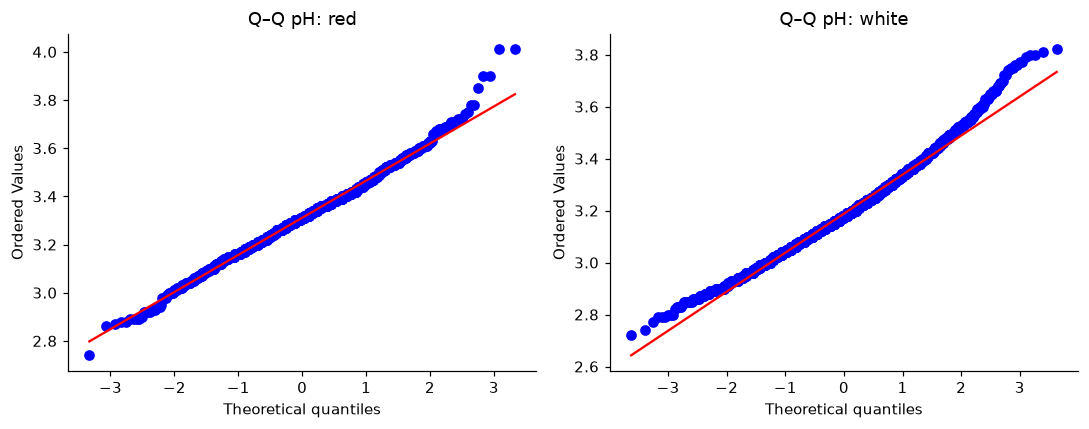

In [ ]:
def holm(p):
    p=np.asarray(p,dtype=float); order=np.argsort(p); m=len(p)
    out=np.empty(m);out[order]=np.minimum(1,np.maximum.accumulate((m-np.arange(m))*p[order]))
    return out

def fitted_normal_d(x):
    x=np.sort(x,axis=-1); n=x.shape[-1]
    mu=x.mean(axis=-1,keepdims=True);sd=x.std(axis=-1,ddof=1,keepdims=True)
    f=stats.norm.cdf((x-mu)/sd)
    return np.maximum(np.max(np.arange(1,n+1)/n-f,axis=-1),np.max(f-np.arange(n)/n,axis=-1))

normal_rows=[]
for k,(c,g) in enumerate([('all',df),*list(df.groupby('wine_type'))]):
    x=g.pH.to_numpy(); d=float(fitted_normal_d(x)); null=[];r=rng_for(10+k)
    for start in range(0,999,50):
        sim=np.round(r.normal(x.mean(),x.std(ddof=1),size=(min(50,999-start),len(x))),2)
        null.extend(fitted_normal_d(sim))
    p=(1+np.count_nonzero(np.asarray(null)>=d))/(len(null)+1)
    normal_rows.append({'тип':c,'n':len(x),'KS_D':d,'p_boot':p})
normality=pd.DataFrame(normal_rows);normality['p_Holm']=holm(normality.p_boot)
normality['решение']=np.where(normality.p_Holm<ALPHA,'отклонить H0','принять H0')
display(normality)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,c in zip(axes,['red','white']):
    stats.probplot(df.loc[df.wine_type.eq(c),'pH'],dist='norm',plot=ax);ax.set_title(f'Q–Q pH: {c}')
fig.tight_layout();plt.show()

## Связи внутри пар
Для исследования связей между pH, сахаром и этанолом используем коэффициенты корреляции Пирсона и Спирмена. Коэффициент Пирсона поможет оценить линейную связь. Коэффициент Спирмена покажет, увеличивается или уменьшается один показатель при увеличении другого, даже если связь не похожа на прямую линию.

Оба коэффициента рассчитаем для каждой пары показателей отдельно среди красных вин, белых вин и всех образцов вместе.

Проверяем три пары:

*   pH - сахар
*   pH - этанол
*   сахар - этанол

Мы проводим много проверок, поэтому возрастает риск случайно получить значимый результат, чтобы снизить этот риск, используем поправку Холма, применяем её отдельно к проверкам корреляции и к проверкам по таблицам сопряжённости.

Будем учитывать p-value, но и величину коэффициента связи, что бы снизить погрешность. Наличие связи также не означает, что один показатель является причиной изменения другого.

Сравниваем результаты для красного и белого вина отдельно и вместе. Это помогает увидеть, как объединение двух типов вина влияет на полученные связи.

,тип,X,Y,метод,коэфф.,p,p_Holm
0,all,pH,residual sugar,Pearson,-0.26732,1.00093e-106,1.4013e-105
1,all,pH,residual sugar,Spearman,-0.229344,2.67895e-78,3.48263e-77
2,all,pH,alcohol,Pearson,0.121248,1.046e-22,8.36798e-22
3,all,pH,alcohol,Spearman,0.140225,6.87243e-30,6.87243e-29
4,all,residual sugar,alcohol,Pearson,-0.359415,2.28406e-197,3.65449e-196
5,all,residual sugar,alcohol,Spearman,-0.329218,4.78079e-164,7.17119e-163
6,red,pH,residual sugar,Pearson,-0.0856524,0.000606591,0.00121318
7,red,pH,residual sugar,Spearman,-0.089971,0.000315527,0.00094658
8,red,pH,alcohol,Pearson,0.205633,9.9645e-17,5.9787e-16
9,red,pH,alcohol,Spearman,0.179932,4.20922e-13,2.10461e-12


,тип,X,Y,chi2,df,min_expected,Cramer_V,p,p_Holm,зависимость обнаружена
0,all,pH,residual sugar,629.613,9,376.255,0.17973,9.19721e-130,6.43805e-129,True
1,all,pH,alcohol,239.062,9,342.116,0.110749,2.02615e-46,1.01307e-45,True
2,all,residual sugar,alcohol,882.159,9,342.773,0.212744,4.31784e-184,3.45427e-183,True
3,red,pH,residual sugar,46.0944,9,85.9193,0.0980256,5.78387e-07,1.15677e-06,True
4,red,pH,alcohol,67.2673,9,91.2439,0.118418,5.2158e-11,1.56474e-10,True
5,red,residual sugar,alcohol,33.8656,9,83.6992,0.0840224,9.4297e-05,9.4297e-05,True
6,white,pH,residual sugar,263.527,9,285.814,0.133919,1.3841e-51,8.30459e-51,True
7,white,pH,alcohol,236.138,9,267.877,0.126769,8.37477e-46,3.34991e-45,True
8,white,residual sugar,alcohol,1355.52,9,280.622,0.303726,3.15153e-286,2.83638e-285,True


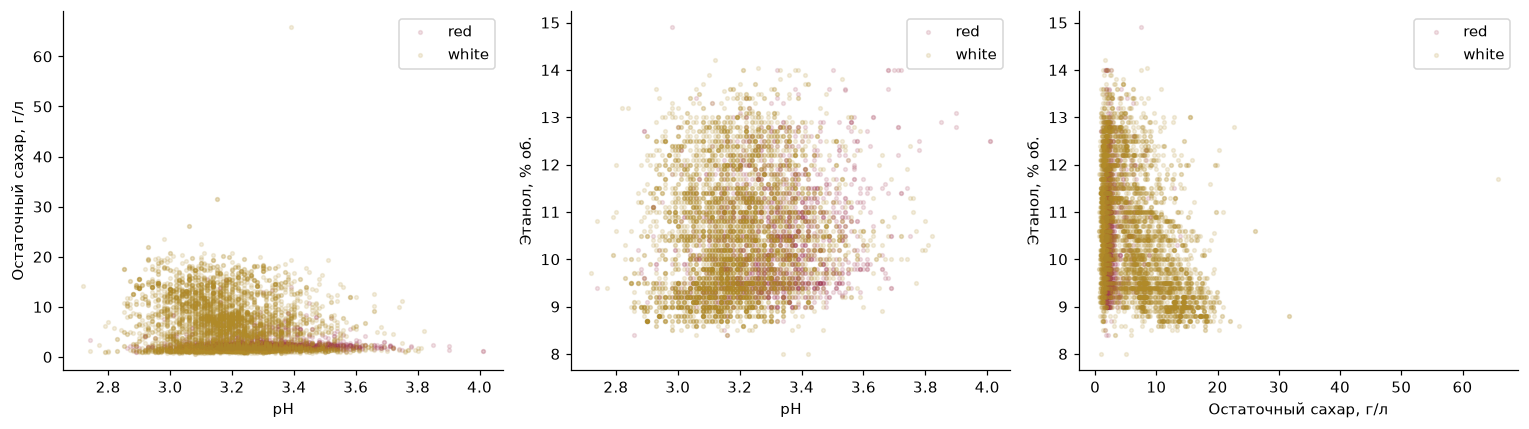

In [ ]:
corr_rows=[];ind_rows=[]
for c,g in [('all',df),*list(df.groupby('wine_type'))]:
    for a,b in combinations(COLS,2):
        for name,fun in [('Pearson',stats.pearsonr),('Spearman',stats.spearmanr)]:
            res=fun(g[a],g[b]);corr_rows.append({'тип':c,'X':a,'Y':b,'метод':name,'коэфф.':res.statistic,'p':res.pvalue})
        tab=pd.crosstab(pd.qcut(g[a],4,duplicates='drop'),pd.qcut(g[b],4,duplicates='drop'))
        chi,p,dof,expected=stats.chi2_contingency(tab,correction=False)
        assert expected.min()>=5, 'Нужна перестановочная калибровка'
        ind_rows.append({'тип':c,'X':a,'Y':b,'chi2':chi,'df':dof,'min_expected':expected.min(),
                         'Cramer_V':np.sqrt(chi/(len(g)*min(np.array(tab.shape)-1))),'p':p})
correlations=pd.DataFrame(corr_rows);correlations['p_Holm']=holm(correlations.p)
independence=pd.DataFrame(ind_rows);independence['p_Holm']=holm(independence.p)
independence['зависимость обнаружена']=independence.p_Holm<ALPHA
display(correlations);display(independence)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,(a,b) in zip(axes,combinations(COLS,2)):
    for c,g in df.groupby('wine_type'):
        ax.scatter(g[a],g[b],s=6,alpha=.15,c=COLORS[c],label=c,rasterized=True)
    ax.set(xlabel=LABELS[a],ylabel=LABELS[b]);ax.legend()
fig.tight_layout();plt.show()

### Различие среднего pH красных и белых вин

Основная содержательная гипотеза: $H_0:\mu_{red}=\mu_{white}$ против $H_1:\mu_{red}\ne\mu_{white}$. Применяем двусторонний t-тест Уэлча без предположения равенства дисперсий. При больших объёмах он использует приближение для выборочных средних. Оцениваем разность и 95% доверительный интервал.
Уровень наблюдений и допущение независимости остаются существенными. Как анализ чувствительности повторяем проверку на уникальных полных строках. Этот пересчёт не устанавливает, какие повторы были ошибками.

In [ ]:
def welch_summary(data,label):
    a=data.loc[data.wine_type.eq('red'),'pH'].to_numpy();b=data.loc[data.wine_type.eq('white'),'pH'].to_numpy()
    va=a.var(ddof=1)/len(a);vb=b.var(ddof=1)/len(b)
    se=np.sqrt(va+vb);dof=(va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1))
    delta=a.mean()-b.mean();margin=stats.t.ppf(.975,dof)*se
    test=stats.ttest_ind(a,b,equal_var=False)
    return {'данные':label,'Δ pH (red-white)':delta,'CI95_low':delta-margin,'CI95_high':delta+margin,
            't':test.statistic,'df':dof,'p':test.pvalue,'решение':'отвергнуть H0' if test.pvalue<ALPHA else 'не отвергать H0'}
welch_table=pd.DataFrame([welch_summary(df,'все строки'),welch_summary(df.drop_duplicates(),'без полных повторов')])
display(welch_table)
dedup_corr=[]
for c,g in df.drop_duplicates().groupby('wine_type'):
    for a,b in combinations(COLS,2):
        dedup_corr.append({'тип':c,'X':a,'Y':b,'Spearman без повторов':stats.spearmanr(g[a],g[b]).statistic})
display(pd.DataFrame(dedup_corr))

,данные,Δ pH (red-white),CI95_low,CI95_high,t,df,p,решение
0,все строки,0.122847,0.114174,0.131519,27.7755,2667.07,2.34226e-149,отвергнуть H0
1,без полных повторов,0.114328,0.104825,0.123832,23.5918,2309.19,1.98003e-110,отвергнуть H0


,тип,X,Y,Spearman без повторов
0,red,pH,residual sugar,-0.0915427
1,red,pH,alcohol,0.183005
2,red,residual sugar,alcohol,0.112205
3,white,pH,residual sugar,-0.153187
4,white,pH,alcohol,0.11942
5,white,residual sugar,alcohol,-0.378605


## Нормализация и стандартизация

Под стандартизацией понимаем $z=(x-\bar x_{train})/s_{train}$, под min–max-нормализацией $(x-\min_{train})/(\max_{train}-\min_{train})$. Преобразования обучаем на train. Контрольные значения могут выходить за $[0,1]$. Для сахара дополнительно исследуем $\log x$ и устойчивое масштабирование $(x-\mathrm{median})/IQR$.

Если $X\sim N(\mu,\sigma^2)$ и параметры известны, $Z=(X-\mu)/\sigma\sim N(0,1)$. При оценённых параметрах это лишь приближение, стандартизация произвольного распределения не делает его нормальным.

,train z mean,train z std,holdout z mean,holdout min–max min,holdout min–max max,skew исходная,skew log
pH,-1.2469e-15,1,0.0045318,-0.015748,0.874016,0.415624,0.255998
residual sugar,-8.75019e-17,1,-0.0265791,0.00306748,0.299847,1.50386,0.228101
alcohol,-1.78285e-15,1,-0.0211079,0,1.1129,0.557229,0.376812


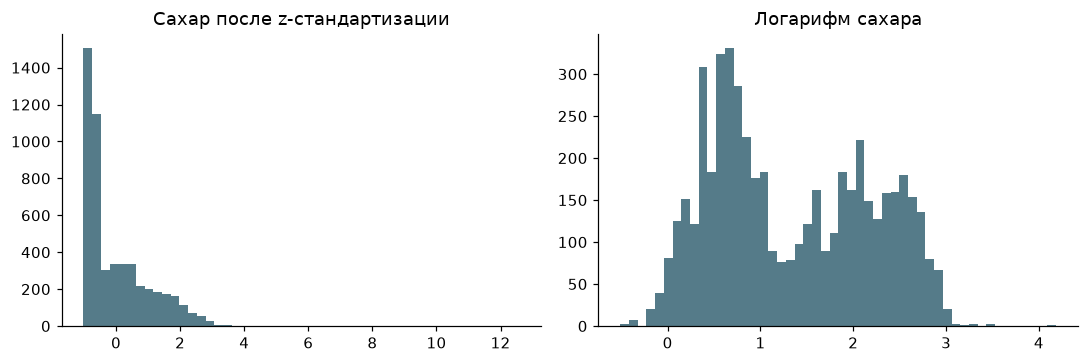

In [ ]:
mu=train[COLS].mean();sd=train[COLS].std(ddof=1)
ztrain=(train[COLS]-mu)/sd;zhold=(holdout[COLS]-mu)/sd
span=train[COLS].max()-train[COLS].min()
mmtrain=(train[COLS]-train[COLS].min())/span
mmhold=(holdout[COLS]-train[COLS].min())/span
robust=(train[COLS]-train[COLS].median())/(train[COLS].quantile(.75)-train[COLS].quantile(.25))
display(pd.DataFrame({'train z mean':ztrain.mean(),'train z std':ztrain.std(ddof=1),
 'holdout z mean':zhold.mean(),'holdout min–max min':mmhold.min(),'holdout min–max max':mmhold.max(),
 'skew исходная':train[COLS].skew(),'skew log':np.log(train[COLS]).skew()}))
assert np.allclose(ztrain.mean(),0,atol=1e-12) and np.allclose(ztrain.std(ddof=1),1)
fig,ax=plt.subplots(1,2,figsize=(10,3.4))
ax[0].hist(ztrain['residual sugar'],bins=50,color='#557b89');ax[0].set_title('Сахар после z-стандартизации')
ax[1].hist(np.log(train['residual sugar']),bins=50,color='#557b89');ax[1].set_title('Логарифм сахара')
fig.tight_layout();plt.show()

## Выборка из конечной опорной совокупности

Берём простую случайную выборку размера $n=650$ двумя способами 1) с возвращениеми 2) без возвращением. В первом случае строки независимы условно на фиксированной таблице; одна строка может попасть несколько раз. Во втором индексы различны, но выбранные строки зависимы из-за механизма отбора.

Обозначим $\mu_N=N^{-1}\sum_i x_i$, $\sigma_N^2=N^{-1}\sum_i(x_i-\mu_N)^2$, $S_N^2=(N-1)^{-1}\sum_i(x_i-\mu_N)^2$. Тогда
$$\mathrm{Var}(\bar X) = \frac{\sigma_N^2}{n}\quad\text{с возвращением};\qquad
\mathrm{Var}(\bar X)=\left(1-\frac nN\right)\frac{S_N^2}{n}\quad\text{без возвращения}.$$

Обычная $s^2$ с делителем $n-1$ несмещённо оценивает $\sigma_N^2$ при возвращении и $S_N^2$ без возвращения. Поэтому целевые дисперсии ниже намеренно различаются. Для среднего строим приближённый 95% интервал с оценкой стандартной ошибки и соответствующей поправкой на конечность. Одно попадание в интервал не доказывает репрезентативность, дополнительно оцениваем покрытие при повторении отбора.

In [ ]:
sample_rows=[];sample_type_rows=[]
n_sample=650
for offset,replace in enumerate([True,False]):
    idx=rng_for(30+offset).choice(N,n_sample,replace=replace);s=df.iloc[idx]
    mode='с возвращением' if replace else 'без возвращения'
    sample_type_rows.append({'отбор':mode,'уникальных индексов':len(np.unique(idx)),
       'доля red в выборке':s.wine_type.eq('red').mean(),'доля red в совокупности':df.wine_type.eq('red').mean()})
    for col in COLS:
        x=s[col].to_numpy();pop=df[col].to_numpy();target=pop.var(ddof=0 if replace else 1)
        se=x.std(ddof=1)/np.sqrt(n_sample)*np.sqrt(1 if replace else 1-n_sample/N)
        margin=stats.t.ppf(.975,n_sample-1)*se
        sample_rows.append({'отбор':mode,'величина':col,'mean_N':pop.mean(),'mean_n':x.mean(),
           'ошибка среднего':x.mean()-pop.mean(),'variance_target':target,'s²':x.var(ddof=1),
           'median_N':np.median(pop),'median_n':np.median(x),
           'CI95_low':x.mean()-margin,'CI95_high':x.mean()+margin,
           'покрывает μ_N':abs(x.mean()-pop.mean())<=margin})
sample_table=pd.DataFrame(sample_rows);display(sample_table);display(pd.DataFrame(sample_type_rows))

,отбор,величина,mean_N,mean_n,ошибка среднего,variance_target,s²,median_N,median_n,CI95_low,CI95_high,покрывает μ_N
0,с возвращением,pH,3.2185,3.22926,0.0107607,0.0258485,0.0260475,3.21,3.21,3.21683,3.24169,True
1,с возвращением,residual sugar,5.44324,5.58123,0.137995,22.6332,21.6332,3,3.4,5.223,5.93946,True
2,с возвращением,alcohol,10.4918,10.5326,0.0408299,1.42234,1.43024,10.3,10.3,10.4405,10.6247,True
3,без возвращения,pH,3.2185,3.21518,-0.00331623,0.0258525,0.025143,3.21,3.2,3.2036,3.22677,True
4,без возвращения,residual sugar,5.44324,5.70654,0.263303,22.6367,29.576,3,3.2,5.30918,6.1039,True
5,без возвращения,alcohol,10.4918,10.4938,0.00204532,1.42256,1.35239,10.3,10.4,10.4089,10.5788,True


,отбор,уникальных индексов,доля red в выборке,доля red в совокупности
0,с возвращением,615,0.255385,0.246114
1,без возвращения,650,0.24,0.246114


### Состоятельность оценок: теория и эмпирический эксперимент

Для независимого и одинаково распределённые наблюдений с конечным вторым моментом закон больших чисел даёт $\bar X_n\to E(X)$ по вероятности. Для состоятельности дисперсии используем представление $s_n^2=\frac n{n-1}(\overline{X^2}-\bar X_n^2)$ и закон больших чисел для $X^2$. Это требует конечного второго момента. В нашем конечном эмпирическом распределении все моменты конечны.

Рисуем  по 400 независимым повторениям каждого объёма для среднего и дисперсии, сравниваем дисперсию среднего с формулой выше и оцениваем покрытие интервалов.
При возвращении можно увеличивать $n$ неограниченно, это иллюстрация классической состоятельности относительно эмпирической совокупности. Без возвращения $n\leq N$; при $n=N$ ошибка равна нулю. Для фиксированного $N$ это исчерпание совокупности, не отдельное доказательство предельной теоремы при $n\to\infty$.

,отбор,n,величина,bias_mean,RMSE_mean,bias_s²,RMSE_s²,Var_mean_emp,Var_mean_theory,coverage_95
0,с возвращением,20,pH,0.000422903,0.0346047,0.000320317,0.00958479,0.00120031,0.00129243,0.9425
1,с возвращением,20,residual sugar,-0.0133541,1.03944,-0.250369,11.7447,1.08296,1.13166,0.945
2,с возвращением,20,alcohol,-0.0122567,0.246502,-0.0291937,0.378296,0.060765,0.0711171,0.965
12,с возвращением,650,pH,3.09611e-05,0.00634706,-1.89984e-05,0.0016611,4.03852e-05,3.9767e-05,0.9425
13,с возвращением,650,residual sugar,-0.00383919,0.185292,0.00552388,2.17723,0.0344043,0.0348203,0.9525
14,с возвращением,650,alcohol,-0.00236651,0.0470467,-0.000448473,0.0682492,0.00221333,0.00218822,0.9425
21,с возвращением,6497,pH,0.00011822,0.00199107,2.24504e-05,0.000454428,3.96027e-06,3.97854e-06,0.965
22,с возвращением,6497,residual sugar,0.00331357,0.0583897,0.0212534,0.717181,0.00340689,0.00348364,0.95
23,с возвращением,6497,alcohol,0.000537227,0.0141405,0.00139441,0.0207552,0.000200165,0.000218923,0.95
24,без возвращения,20,pH,5.91535e-05,0.0371219,-0.000183898,0.00921795,0.00138149,0.00128865,0.945


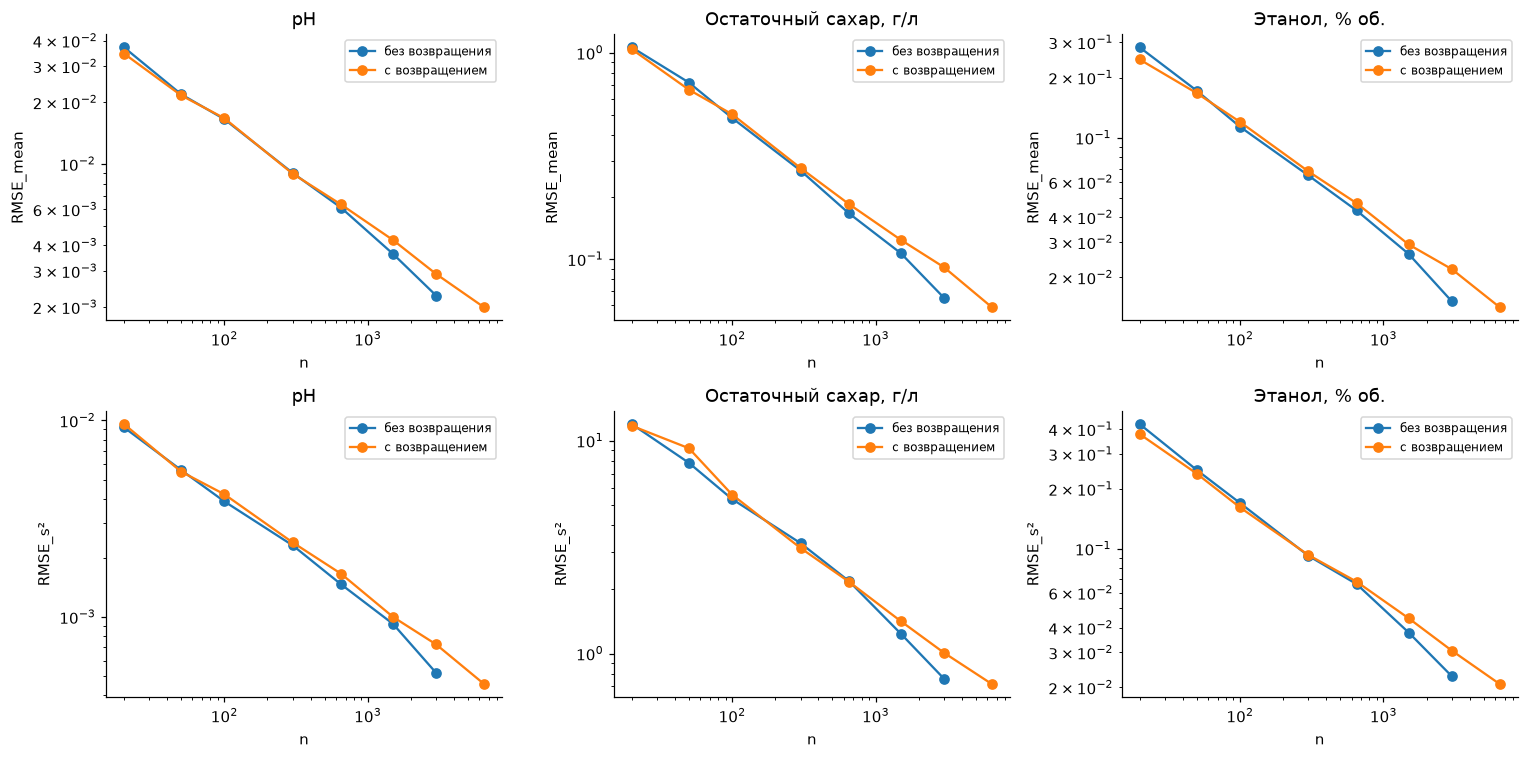

MC стандартная ошибка покрытия около 0.95: 0.010897247358851683
При n=N без возвращения RMSE≈0: значение приведено в таблице и пропущено на логарифмической оси.


In [ ]:
est_rows=[];R=400;sizes=[20,50,100,300,650,1500,3000,N]
data=df[COLS].to_numpy();pop_mu=data.mean(axis=0)
for offset,replace in enumerate([True,False]):
    r=rng_for(40+offset);target=data.var(axis=0,ddof=0 if replace else 1)
    for n in sizes:
        if replace:
            idx=r.integers(0,N,size=(R,n))
        else:
            idx=np.array([r.choice(N,n,replace=False) for _ in range(R)])
        sim=data[idx];means=sim.mean(axis=1);variances=sim.var(axis=1,ddof=1)
        factor=1 if replace else 1-n/N
        se=np.sqrt(variances/n*factor)
        cover=np.mean(np.abs(means-pop_mu)<=stats.t.ppf(.975,n-1)*se+1e-12,axis=0)
        for j,col in enumerate(COLS):
            est_rows.append({'отбор':'с возвращением' if replace else 'без возвращения','n':n,'величина':col,
                'bias_mean':np.mean(means[:,j]-pop_mu[j]),
                'RMSE_mean':np.sqrt(np.mean((means[:,j]-pop_mu[j])**2)),
                'bias_s²':np.mean(variances[:,j]-target[j]),
                'RMSE_s²':np.sqrt(np.mean((variances[:,j]-target[j])**2)),
                'Var_mean_emp':means[:,j].var(ddof=1),'Var_mean_theory':target[j]*factor/n,
                'coverage_95':cover[j]})
        del sim,idx
estimates=pd.DataFrame(est_rows)
display(estimates.loc[estimates.n.isin([20,650,N])])
fig,axes=plt.subplots(2,3,figsize=(14,7))
for j,col in enumerate(COLS):
    for mode,g in estimates.loc[estimates['величина'].eq(col)].groupby('отбор'):
        for i,key in enumerate(['RMSE_mean','RMSE_s²']):
            positive=g[key]>1e-10
            axes[i,j].loglog(g.loc[positive,'n'],g.loc[positive,key],'o-',label=mode)
            axes[i,j].set(xlabel='n',ylabel=key,title=LABELS[col]);axes[i,j].legend(fontsize=8)
fig.tight_layout();plt.show()
print('MC стандартная ошибка покрытия около 0.95:', np.sqrt(.95*.05/R))
print('При n=N без возвращения RMSE≈0: значение приведено в таблице и пропущено на логарифмической оси.')


### Выводы для первой части лабораторной

Следующая ячейка формирует выводы из рассчитанных таблиц.

In [ ]:
lines=[]
for c,g in df.groupby('wine_type'):
    lines.append(f"- **{c}:** среднее pH {g.pH.mean():.4f}; сахар {g['residual sugar'].mean():.3f} г/л; этанол {g.alcohol.mean():.3f}% об.")
for _,r in normality.iterrows():
    lines.append(f"- Нормальность округлённого pH, **{r['тип']}**: p с поправкой Холма = {r.p_Holm:.4g}; {r['решение']}.")
for (c,v),g in fit_table.groupby(['тип','величина']):
    if v=='pH': continue
    best=g.loc[g.NLL_holdout.idxmin()]
    lines.append(f"- {c}, {v}: среди кандидатов меньший контрольный NLL у **{best['модель']}**; параметры SciPy {best['параметры SciPy']}, KS D на контроле {best.KS_D_holdout:.3f}. Это относительное приближение, а не установленный точный закон.")
lines.append('- Для всех трёх величин эмпирическое распределение остаётся непосредственно наблюдаемым описанием. Пики и хвосты сахара и этанола дают основания осторожно относиться к однокомпонентным моделям.')
w=welch_table.iloc[0]
lines.append(f"- Красное минус белое: ΔpH={w['Δ pH (red-white)']:.4f}, 95% CI [{w.CI95_low:.4f}; {w.CI95_high:.4f}], p={w.p:.3g}. Вывод относится к принятому допущению независимых строк.")
for _,r in independence.iterrows():
    decision='обнаружена зависимость' if r['зависимость обнаружена'] else 'зависимость не обнаружена выбранным разбиением'
    lines.append(f"- {r['тип']}, {r.X} / {r.Y}: V={r.Cramer_V:.3f}, p_Holm={r.p_Holm:.3g}; {decision}.")
lines.append('- RMSE оценивает типичную ошибку, а не гарантирует монотонного улучшения каждой отдельной выборки. При полном отборе без возвращения характеристики совпадают с опорной совокупностью.')
display(Markdown('\n'.join(lines)))

- **red:** среднее pH 3.3111; сахар 2.539 г/л; этанол 10.423% об.
- **white:** среднее pH 3.1883; сахар 6.391 г/л; этанол 10.514% об.
- Нормальность округлённого pH, **all**: p с поправкой Холма = 0.003; отклонить H0.
- Нормальность округлённого pH, **red**: p с поправкой Холма = 0.003; отклонить H0.
- Нормальность округлённого pH, **white**: p с поправкой Холма = 0.003; отклонить H0.
- red, alcohol: среди кандидатов меньший контрольный NLL у **lognormal**; параметры SciPy (0.098922, 0.0, 10.366379), KS D на контроле 0.121. Это относительное приближение, а не установленный точный закон.
- red, residual sugar: среди кандидатов меньший контрольный NLL у **lognormal**; параметры SciPy (0.359743, 0.0, 2.338752), KS D на контроле 0.172. Это относительное приближение, а не установленный точный закон.
- white, alcohol: среди кандидатов меньший контрольный NLL у **lognormal**; параметры SciPy (0.115367, 0.0, 10.451962), KS D на контроле 0.087. Это относительное приближение, а не установленный точный закон.
- white, residual sugar: среди кандидатов меньший контрольный NLL у **lognormal**; параметры SciPy (0.923867, 0.0, 4.41737), KS D на контроле 0.117. Это относительное приближение, а не установленный точный закон.
- Для всех трёх величин эмпирическое распределение остаётся непосредственно наблюдаемым описанием. Пики и хвосты сахара и этанола дают основания осторожно относиться к однокомпонентным моделям.
- Красное минус белое: ΔpH=0.1228, 95% CI [0.1142; 0.1315], p=2.34e-149. Вывод относится к принятому допущению независимых строк.
- all, pH / residual sugar: V=0.180, p_Holm=6.44e-129; обнаружена зависимость.
- all, pH / alcohol: V=0.111, p_Holm=1.01e-45; обнаружена зависимость.
- all, residual sugar / alcohol: V=0.213, p_Holm=3.45e-183; обнаружена зависимость.
- red, pH / residual sugar: V=0.098, p_Holm=1.16e-06; обнаружена зависимость.
- red, pH / alcohol: V=0.118, p_Holm=1.56e-10; обнаружена зависимость.
- red, residual sugar / alcohol: V=0.084, p_Holm=9.43e-05; обнаружена зависимость.
- white, pH / residual sugar: V=0.134, p_Holm=8.3e-51; обнаружена зависимость.
- white, pH / alcohol: V=0.127, p_Holm=3.35e-45; обнаружена зависимость.
- white, residual sugar / alcohol: V=0.304, p_Holm=2.84e-285; обнаружена зависимость.
- RMSE оценивает типичную ошибку, а не гарантирует монотонного улучшения каждой отдельной выборки. При полном отборе без возвращения характеристики совпадают с опорной совокупностью.

### Lab resume — cat_mark_table

Идентификаторы `S1.*` ниже — локальная карта разделов работы. Официальные `cat_id` и коэффициенты (`coeff`) в предоставленных материалах не указаны, поэтому их нельзя достоверно заполнить: коэффициент оставлен пустым для преподавателя.

| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| S1.1 | Часть 1 → Dataset |  | Источник и описание датасета |
| S1.2 | Random Variable 01 — pH |  | Описание, EDA и распределение |
| S1.3 | Random Variable 02 — остаточный сахар |  | Описание, EDA и распределение |
| S1.4 | Random Variable 03 — содержание этанола |  | Описание, EDA и распределение |
| S1.5 | Связи внутри пар |  | Корреляции и проверка независимости |
| S1.6 | Различие среднего pH |  | t-тест Уэлча |
| S1.7 | Выборки и состоятельность оценок |  | Оценивание на выборках |


# Lab01 — sprint 2

## Random Variable 01 — генератор измеренного pH белого вина

### Description

Цель — воспроизвести маргинальное эмпирическое распределение записанного pH белого вина. Обучение генератора проводится только на обучающей выборке (`train`), а качество переноса проверяется на отложенной выборке (`holdout`).

### Math desc

Для наблюдений $x_1,\ldots,x_n$ строим эмпирическое распределение на уникальных значениях pH.

Генерация по обратной функции выбирает значение по накопленным вероятностям. Alias-метод реализует тот же дискретный закон другим алгоритмом. Для сравнения также используется параметрическая нормальная модель.

### Code

Ниже реализованы генераторы, диагностические расчёты и сравнение с отложенными данными.


### Code — метод обратного преобразования



Реализация обратного преобразования для дискретного эмпирического закона. Выход содержит значения pH, а не индексы строк.

In [ ]:
class EmpiricalInverse:
    def __init__(self, observations):
        x=np.asarray(observations,dtype=float)
        if x.ndim!=1 or x.size==0 or not np.isfinite(x).all():
            raise ValueError('Нужен непустой одномерный массив конечных чисел')
        self.values,counts=np.unique(x,return_counts=True)
        self.p=counts/counts.sum();self.cdf=np.cumsum(self.p);self.cdf[-1]=1.0
    def ppf(self,u):
        u=np.asarray(u,dtype=float)
        if not np.isfinite(u).all() or np.any((u<0)|(u>=1)):
            raise ValueError('u должно принадлежать [0,1)')
        return self.values[np.searchsorted(self.cdf,u,side='right')]
    def rvs(self,size,rng):
        if isinstance(size,bool) or not isinstance(size,(int,np.integer)) or size<0:
            raise ValueError('size должно быть целым неотрицательным')
        return self.ppf(rng.random(size))

ph_train=train.loc[train.wine_type.eq('white'),'pH'].to_numpy()
ph_test=holdout.loc[holdout.wine_type.eq('white'),'pH'].to_numpy()
generator=EmpiricalInverse(ph_train)
generated=generator.rvs(100_000,rng_for(60))
print('Обучение:',len(ph_train),'Контроль:',len(ph_test),'Масс:',len(generator.values))
print('Первые 15 значений:',generated[:15])

Обучение: 3918 Контроль: 980 Масс: 99
Первые 15 значений: [3.2  2.9  3.12 2.97 3.   3.21 3.05 3.36 3.54 3.2  3.28 3.74 3.12 3.38
 3.21]


### Code — альтернативный алгоритм: alias-метод

Те же дискретные массы можно генерировать через $K$ равновероятных столбцов единичной высоты. В каждом храним порог $q_j$ и дополнительный исход $a_j$. Сначала $J$ равномерно на $\{0,\dots,K-1\}$, затем независимое $V\sim U[0,1)$; при $V<q_J$ возвращаем $v_J$, иначе $v_{a_J}$.

Корректность удобно проверить детерминированно: суммарная масса исхода $i$ равна
$$p_i^{alias}=\frac1K\left(q_i+\sum_{j:a_j=i}(1-q_j)\right).$$
Алгоритм подготовки переносит избыток из столбцов с $Kp_j>1$ в столбцы с $Kp_j<1$, сохраняя массы исходов. Поэтому после заполнения столбцов выражение равно исходному $p_i$. Подготовка после подсчёта частот $O(K)$, генерация одного значения $O(1)$; нужны два случайных выбора и дополнительная память. Метод полезен при большом числе вызовов неизменного распределения.

In [ ]:
class EmpiricalAlias(EmpiricalInverse):
    def __init__(self,observations):
        super().__init__(observations)
        k=len(self.p);scaled=self.p*k
        self.prob=np.ones(k);self.alias=np.arange(k)
        small=list(np.flatnonzero(scaled<1));large=list(np.flatnonzero(scaled>=1))
        while small and large:
            s=small.pop();l=large.pop();self.prob[s]=scaled[s];self.alias[s]=l
            scaled[l]-=1-scaled[s]
            (small if scaled[l]<1 else large).append(l)
    def rvs(self,size,rng):
        if isinstance(size,bool) or not isinstance(size,(int,np.integer)) or size<0:
            raise ValueError('size должно быть целым неотрицательным')
        j=rng.integers(0,len(self.p),size=size);u=rng.random(size)
        return self.values[np.where(u<self.prob[j],j,self.alias[j])]
    def reconstructed_mass(self):
        k=len(self.p);mass=self.prob/k
        np.add.at(mass,self.alias,(1-self.prob)/k)
        return mass

alias_generator=EmpiricalAlias(ph_train)
alias_sample=alias_generator.rvs(100_000,rng_for(61))
print('Максимальная ошибка восстановления масс:',np.max(np.abs(alias_generator.reconstructed_mass()-alias_generator.p)))

Максимальная ошибка восстановления масс: 8.673617379884035e-18


### Code — параметрическое сравнение

Из независимых $U_1\in(0,1]$, $U_2\in[0,1)$ получаем $R=\sqrt{-2\ln U_1}$, $\Theta=2\pi U_2$, $Z_1=R\cos\Theta$, $Z_2=R\sin\Theta$. Совместная плотность после перехода к декартовым координатам равна $(2\pi)^{-1}e^{-(z_1^2+z_2^2)/2}=\phi(z_1)\phi(z_2)$, то есть оба значения независимы и стандартно нормальны. Затем $X=\hat\mu+\hat\sigma Z$; для сопоставления с файлом округляем pH до 0,01.


,источник,n,mean,var_ddof0,std_ddof0,q05,q25,median,q75,q95,min,max
0,train (цель),3918,3.18794,0.022621,0.150403,2.96,3.08,3.18,3.28,3.46,2.74,3.81
1,holdout,980,3.18957,0.0234961,0.153285,2.94,3.09,3.18,3.28,3.45,2.72,3.82
2,inverse,100000,3.18741,0.0228363,0.151117,2.96,3.08,3.18,3.28,3.46,2.74,3.81
3,alias,100000,3.18855,0.0226065,0.150354,2.96,3.08,3.18,3.28,3.46,2.74,3.81
4,normal rounded,100000,3.18887,0.0227058,0.150684,2.94,3.09,3.19,3.29,3.44,2.49,3.94


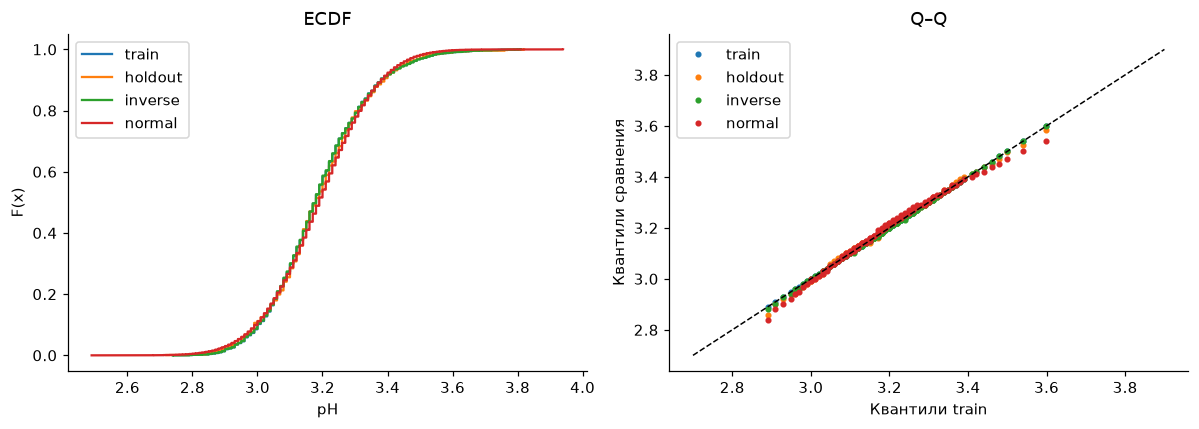

In [ ]:
def box_muller(size,rng):
    pairs=(size+1)//2
    u1=1-rng.random(pairs);u2=rng.random(pairs)
    radius=np.sqrt(-2*np.log(u1));angle=2*np.pi*u2
    return np.column_stack([radius*np.cos(angle),radius*np.sin(angle)]).ravel()[:size]

normal_sample=np.round(ph_train.mean()+ph_train.std(ddof=0)*box_muller(100_000,rng_for(62)),2)

def metric_row(x,name):
    q=np.quantile(x,[.05,.25,.5,.75,.95])
    return dict(zip(['источник','n','mean','var_ddof0','std_ddof0','q05','q25','median','q75','q95','min','max'],
           [name,len(x),np.mean(x),np.var(x),np.std(x),*q,np.min(x),np.max(x)]))
generator_metrics=pd.DataFrame([metric_row(x,name) for name,x in [
    ('train (цель)',ph_train),('holdout',ph_test),('inverse',generated),('alias',alias_sample),('normal rounded',normal_sample)]])
display(generator_metrics)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,x in [('train',ph_train),('holdout',ph_test),('inverse',generated),('normal',normal_sample)]:
    v=np.sort(x);axes[0].step(v,np.arange(1,len(v)+1)/len(v),where='post',label=name)
    q=np.linspace(.01,.99,99);axes[1].plot(np.quantile(ph_train,q),np.quantile(x,q),'.',label=name)
axes[0].set(xlabel='pH',ylabel='F(x)',title='ECDF');axes[0].legend()
axes[1].plot([2.7,3.9],[2.7,3.9],'k--',lw=1);axes[1].set(xlabel='Квантили train',ylabel='Квантили сравнения',title='Q–Q');axes[1].legend()
fig.tight_layout();plt.show()

### Tests — автотесты реализации

Отделяем **корректность реализации** от **качества модели**.

Для реализации проверяем в том числе границы CDF, воспроизводимость, постоянные данные, пустой размер, ошибочные входы, сохранение дискретных масс. Для сравнения с обучающей ECDF используем DKW-границу
$$P(\sup_x|F_m(x)-\hat F_{train}(x)|>\varepsilon)\leq2e^{-2m\varepsilon^2}.$$
Условно на train это корректная проверка сгенерированной выборки на заданное распределение, включая дискретный случай. Выбираем $\alpha=0.001$ для каждого из двух генераторов. Вероятность хотя бы одного случайного отказа ограничена 0,002.

Для среднего ожидаем стандартную ошибку $\sigma/\sqrt m$; печатаем отклонение в этих единицах. Для дисперсии приводим приближённую ошибку через четвёртый центральный момент. Эти диагностики не выбирают и не меняют seed после результата.

In [ ]:
test_results=[]
def check(name,condition):
    condition=bool(condition);test_results.append({'проверка':name,'статус':'PASS' if condition else 'FAIL'})
    assert condition,name
def raises_value_error(fn):
    try: fn()
    except ValueError: return True
    return False

check('Inverse: одинаковый seed',np.array_equal(generator.rvs(100,rng_for(80)),generator.rvs(100,rng_for(80))))
check('Alias: одинаковый seed',np.array_equal(alias_generator.rvs(100,rng_for(81)),alias_generator.rvs(100,rng_for(81))))
check('Область значений inverse',np.isin(generated,generator.values).all())
check('Область значений alias',np.isin(alias_sample,generator.values).all())
check('Число значений и конечность',generated.shape==(100000,) and np.isfinite(generated).all())
check('Шаг записи 0.01',np.allclose(generated*100,np.round(generated*100)))
check('Нулевой размер',generator.rvs(0,rng_for()).size==0 and alias_generator.rvs(0,rng_for()).size==0)
check('Постоянная выборка inverse',np.all(EmpiricalInverse([3.2]*5).rvs(100,rng_for())==3.2))
check('Постоянная выборка alias',np.all(EmpiricalAlias([3.2]*5).rvs(100,rng_for())==3.2))
for invalid in [[],[np.nan],[np.inf],[[1,2]]]:
    check('Отклонён неверный вход '+repr(invalid),raises_value_error(lambda:EmpiricalInverse(invalid)))
for size in [-1,1.5,True]:
    check('Отклонён размер '+repr(size),raises_value_error(lambda:generator.rvs(size,rng_for())))
check('u вне диапазона',raises_value_error(lambda:generator.ppf([1.])))
check('Левая граница',generator.ppf([0.])[0]==generator.values[0])
check('Правая допустимая граница',generator.ppf([np.nextafter(1.,0.)])[0]==generator.values[-1])
check('Точные внутренние границы',np.array_equal(generator.ppf(generator.cdf[:-1]),generator.values[1:]))
check('Все массы alias',np.allclose(alias_generator.reconstructed_mass(),alias_generator.p,rtol=1e-12,atol=1e-14))
for toy in [[0,1,1,1],[0,0,1,2,3,3,3,3],[5],[0,1,2,3]]:
    a=EmpiricalAlias(toy);check('Alias на тестовых массах '+repr(toy),np.allclose(a.reconstructed_mass(),a.p))

grid=generator.values
def cdf_at(x,grid): return np.searchsorted(np.sort(x),grid,side='right')/len(x)
gen_diagnostics=[]
target_mu=ph_train.mean();target_var=ph_train.var();mu4=np.mean((ph_train-target_mu)**4)
for name,x in [('inverse',generated),('alias',alias_sample)]:
    d=np.max(np.abs(cdf_at(x,grid)-generator.cdf));eps=np.sqrt(np.log(2/.001)/(2*len(x)))
    check(name+' DKW',d<=eps)
    gen_diagnostics.append({'метод':name,'CDF_D':d,'DKW_eps':eps,
      'ошибка среднего':x.mean()-target_mu,'mean_error/SE':(x.mean()-target_mu)/np.sqrt(target_var/len(x)),
      'ошибка дисперсии':x.var()-target_var,
      'var_error/SE_approx':(x.var()-target_var)/np.sqrt((mu4-target_var**2)/len(x))})
display(pd.DataFrame(test_results));display(pd.DataFrame(gen_diagnostics))

,проверка,статус
0,Inverse: одинаковый seed,PASS
1,Alias: одинаковый seed,PASS
2,Область значений inverse,PASS
3,Область значений alias,PASS
4,Число значений и конечность,PASS
5,Шаг записи 0.01,PASS
6,Нулевой размер,PASS
7,Постоянная выборка inverse,PASS
8,Постоянная выборка alias,PASS
9,Отклонён неверный вход [],PASS


,метод,CDF_D,DKW_eps,ошибка среднего,mean_error/SE,ошибка дисперсии,var_error/SE_approx
0,inverse,0.00331248,0.00616478,-0.000525671,-1.10554,0.00022235,1.95449
1,alias,0.00293058,0.00616478,0.000124529,0.261898,-4.80606e-05,-0.422459


### Tests — проверка на отложенных данных

Сравнение с train проверяет, правильно ли реализовано распределение, заданное этим же train. Для проверки переноса на новые строки сравниваем с holdout:

1. ECDF train и holdout — качество самой эмпирической модели.
2. Новую независимую выборку генератора размером, равным holdout, и holdout — результат моделирования.
3. Аналогичную выборку нормального генератора и holdout — параметрический ориентир.

Печатаем KS-расстояние и расстояние Вассерштейна W_1 (pH). Из-за повторяющихся значений p-value KS калибруем перестановками объединённых выборок ($B=999$). Внутри этих трёх диагностик применяем Холма. Проверки используют общий holdout и не являются тремя независимыми подтверждениями.
Неприятие гипотезы равенства не означает доказанное совпадение. Формальную эквивалентность можно проверить только после содержательного выбора допустимого различия; такой порог в условии не задан. Здесь вывод о близости основан на численных расстояниях и масштабе pH.

In [ ]:
def permutation_ks(x,y,rng,B=999):
    x=np.asarray(x);y=np.asarray(y);joined=np.r_[x,y]
    support=np.unique(joined)
    cats=np.searchsorted(support,joined);counts=np.bincount(cats,minlength=len(support))
    n=len(x);m=len(y)
    def stat(left):
        return np.max(np.abs(np.cumsum(left)/n-np.cumsum(counts-left)/m))
    observed=stat(np.bincount(cats[:n],minlength=len(support)))
    exceed=0
    for _ in range(B):
        idx=rng.choice(len(joined),n,replace=False)
        exceed+=stat(np.bincount(cats[idx],minlength=len(support)))>=observed-1e-14
    return observed,(exceed+1)/(B+1)

m=len(ph_test)
inverse_check=generator.rvs(m,rng_for(90))
normal_check=np.round(ph_train.mean()+ph_train.std(ddof=0)*box_muller(m,rng_for(91)),2)
holdout_rows=[]
for k,(name,x) in enumerate([('train vs holdout',ph_train),('inverse vs holdout',inverse_check),('normal vs holdout',normal_check)]):
    d,p=permutation_ks(x,ph_test,rng_for(92+k))
    holdout_rows.append({'сравнение':name,'n1':len(x),'n2':m,'KS_D':d,
                         'Wasserstein_pH':stats.wasserstein_distance(x,ph_test),'p_perm':p})
holdout_metrics=pd.DataFrame(holdout_rows);holdout_metrics['p_Holm']=holm(holdout_metrics.p_perm)
holdout_metrics['решение']=np.where(holdout_metrics.p_Holm<ALPHA,'отвергнуть равенство','не отвергать равенство')
display(holdout_metrics)

lag_rows=[]
for name,x in [('inverse',generated),('alias',alias_sample)]:
    for lag in [1,2,5,10]:
        lag_rows.append({'метод':name,'lag':lag,'автокорреляция':np.corrcoef(x[:-lag],x[lag:])[0,1]})
display(pd.DataFrame(lag_rows))
print('Проверка нескольких лагов — диагностика, не доказательство независимости и не аудит качества PCG64.')

,сравнение,n1,n2,KS_D,Wasserstein_pH,p_perm,p_Holm,решение
0,train vs holdout,3918,980,0.032838,0.00682441,0.273,0.819,не отвергать равенство
1,inverse vs holdout,980,980,0.0418367,0.012,0.273,0.819,не отвергать равенство
2,normal vs holdout,980,980,0.0336735,0.00783673,0.505,0.819,не отвергать равенство


,метод,lag,автокорреляция
0,inverse,1,0.00130241
1,inverse,2,-0.00499795
2,inverse,5,0.00474149
3,inverse,10,-0.00496964
4,alias,1,0.00402859
5,alias,2,-0.00403978
6,alias,5,-0.000646109
7,alias,10,-0.00104468


Проверка нескольких лагов — диагностика, не доказательство независимости и не аудит качества PCG64.


### Дополнительный анализ — скорость основных реализаций

Измеряем медиану пяти запусков генерации 100 000 значений без учёта подготовки таблиц. Это сравнение данных реализаций на данном компьютере; оно не заменяет анализ сложности и не гарантирует ускорения alias в векторизованном NumPy.

In [ ]:
speed=[]
for k,(name,obj) in enumerate([('inverse',generator),('alias',alias_generator)]):
    timings=[];r=rng_for(110+k)
    for _ in range(5):
        start=time.perf_counter();obj.rvs(100_000,r);timings.append(time.perf_counter()-start)
    speed.append({'метод':name,'медиана, мс':1000*np.median(timings),'подготовка':'не включена'})
display(pd.DataFrame(speed))

,метод,"медиана, мс",подготовка
0,inverse,5.47887,не включена
1,alias,1.96903,не включена


### Дополнительный анализ — восемь подходов к генерации

Это обзор восьми способов преобразования базовой равномерной случайности. Они не являются восемью новыми PRNG. Основные inverse и alias реализованы и проверены выше, Box–Muller реализован как параметрическое сравнение. Ниже для остальных приведены запускаемые учебные примеры.

| № | Подход, распределения и применение | Механика / пример | Сильная сторона | Ограничение | Источник |
|---|---|---|---|---|---|
| 1 | Обратная CDF; произвольный одномерный закон с доступным квантилем | $X=F^{-1}(U)$; эмпирическое pH | Универсальный принцип | Обращение может быть дорогим | [D86](https://luc.devroye.org/rnbookindex.html), II §2 |
| 2 | Alias; конечное дискретное распределение, многократные симуляции pH | Равномерный столбец + порог | $O(1)$ на значение | Подготовка при смене масс | D86, III §4 |
| 3 | Принятие–отклонение; заданная плотность, здесь Beta(2,2) | Из $g$ принимаем с вероятностью $f/(Mg)$ | Не нужна обратная CDF | Потери попыток; нужно доказать огибающую | D86, II §3 |
| 4 | Box–Muller; нормальный закон, шум измерений | Радиус и угол из двух U | Два нормальных значения | Логарифм и тригонометрия | [D06](https://luc.devroye.org/Devroye-Chapter-4-Nonuniform-Random-VariateGeneration_2006_Handbooks-in-Operations-Research.pdf), §1.2 |
| 5 | Полярный метод Marsaglia; нормальный закон | Точка внутри единичного диска | Без sin/cos | Отбрасывает часть точек | D86, IX §1 |
| 6 | Композиция; смеси распределений разных групп | Сначала тип, затем условный закон | Сохраняет смесь групп | Нужны веса и условные модели | D06, §1 |
| 7 | Сумма экспоненциальных; Erlang $\Gamma(k,\theta)$ при целом k, время ожидания | $X=-\theta\sum_{j=1}^k\log U_j$ | Простой вывод | $k$ равномерных на результат; только целый k | D86, IX §3 |
| 8 | Marsaglia–Tsang; Gamma с произвольной формой, положительные величины | Нормальное предложение + принятие; для $k<1$ преобразование | Эффективен для Gamma | Больше ветвей; сам Gamma может не подойти вину | [MT00](https://doi.org/10.1145/358407.358414) |

Для принятия–отклонения ниже $f(x)=6x(1-x)$ на $[0,1]$, $g(x)=1$, $M=1.5$: $f\leq Mg$. После принятия плотность пропорциональна $g\cdot f/(Mg)=f/M$, то есть равна $f$ после нормировки; вероятность принятия $1/M=2/3$.

В полярном методе выбираем $(V_1,V_2)$ равномерно из квадрата $[-1,1]^2$, оставляем $0<S=V_1^2+V_2^2<1$, возвращаем $V_i\sqrt{-2\log S/S}$. Для композиции $P(X\in A)=\sum_cP(C=c)P(X\in A\mid C=c)$; веса здесь соответствуют только долям строк датасета. В Erlang сумма независимых экспоненциальных даёт гамма-распределение с целой формой.

В методе Marsaglia–Tsang при $k\geq1$: $d=k-1/3$, $c=1/\sqrt{9d}$; для $Z\sim N(0,1)$ берём $v=(1+cZ)^3>0$ и принимаем, если $\log U<Z^2/2+d-dv+d\log v$. Возвращаем $\theta dv$. При $0<k<1$ используем $G_{k+1}U^{1/k}$ с независимым U. Полное доказательство огибающей и констант — в оригинальной статье MT00; здесь они не выдаются за самостоятельно выведенный результат.

In [ ]:
def rejection_beta22(size, rng):
    out = []

    while len(out) < size:
        x = rng.random()
        u = rng.random()

        if u <= 4 * x * (1 - x):
            out.append(x)

    return np.asarray(out)


def polar_normal(size, rng):
    out = []

    while len(out) < size:
        v = rng.uniform(-1, 1, size=2)
        s = v @ v

        if 0 < s < 1:
            out.extend(v * np.sqrt(-2 * np.log(s) / s))

    return np.asarray(out[:size])


def erlang(size, k, theta, rng):
    return -theta * np.log(
        1 - rng.random((size, k))
    ).sum(axis=1)


def gamma_mt(size, k, theta, rng):
    if k <= 0 or theta <= 0:
        raise ValueError(
            'Параметры k и theta должны быть положительными'
        )

    if k < 1:
        return (
            gamma_mt(size, k + 1, theta, rng)
            * (1 - rng.random(size)) ** (1 / k)
        )

    d = k - 1 / 3
    c = 1 / np.sqrt(9 * d)
    out = []

    while len(out) < size:
        z = rng.normal()
        a = 1 + c * z

        if a <= 0:
            continue

        v = a ** 3
        u = 1 - rng.random()

        if np.log(u) < z * z / 2 + d - d * v + d * np.log(v):
            out.append(theta * d * v)

    return np.asarray(out)


def mixture_ph(size, rng):
    red_share = df['wine_type'].eq('red').mean()
    choose_red = rng.random(size) < red_share
    out = np.empty(size)

    for color, mask in [
        ('red', choose_red),
        ('white', ~choose_red)
    ]:
        values = train.loc[
            train['wine_type'] == color, 'pH'
        ]

        gen = EmpiricalInverse(values)
        out[mask] = gen.rvs(int(mask.sum()), rng)

    return out

gallery = {
    'Метод обратной функции — pH': (
        generated,
        ph_train.mean(),
        ph_train.var()
    ),

    'Метод псевдонимов — pH': (
        alias_sample,
        ph_train.mean(),
        ph_train.var()
    ),

    'Метод Неймана — бета-распределение (2; 2)': (
        rejection_beta22(20000, rng_for(120)),
        0.5,
        1 / 20
    ),

    'Метод Бокса — Мюллера — нормальное (0; 1)': (
        box_muller(20000, rng_for(121)),
        0.0,
        1.0
    ),

    'Полярный метод — нормальное (0; 1)': (
        polar_normal(20000, rng_for(122)),
        0.0,
        1.0
    ),

    'Распределение Эрланга (3; 2)': (
        erlang(20000, 3, 2.0, rng_for(123)),
        6.0,
        12.0
    ),

    'Метод Марсальи — Цанга — гамма (2,5; 2)': (
        gamma_mt(20000, 2.5, 2.0, rng_for(124)),
        5.0,
        10.0
    ),

    'Метод Марсальи — Цанга — гамма (0,7; 2)': (
        gamma_mt(20000, 0.7, 2.0, rng_for(125)),
        1.4,
        2.8
    )
}

overview = []

for name, (x, mean, var) in gallery.items():
    overview.append({
        'Пример': name,
        'Среднее по генератору': x.mean(),
        'Среднее по модели': mean,
        'Дисперсия по генератору': x.var(),
        'Дисперсия по модели': var
    })

mix = mixture_ph(20000, rng_for(126))

w = df['wine_type'].eq('red').mean()

rt = train.loc[
    train['wine_type'] == 'red', 'pH'
].to_numpy()

wt = ph_train

mix_mu = w * rt.mean() + (1 - w) * wt.mean()

mix_var = (
    w * (rt.var() + (rt.mean() - mix_mu) ** 2)
    + (1 - w) * (wt.var() + (wt.mean() - mix_mu) ** 2)
)

overview.append({
    'Пример': 'Метод суперпозиции — смесь pH',
    'Среднее по генератору': mix.mean(),
    'Среднее по модели': mix_mu,
    'Дисперсия по генератору': mix.var(),
    'Дисперсия по модели': mix_var
})

display(pd.DataFrame(overview))

,Пример,Среднее по генератору,Среднее по модели,Дисперсия по генератору,Дисперсия по модели
0,Метод обратной функции — pH,3.18867,3.1892,0.0228313,0.0226089
1,Метод псевдонимов — pH,3.18932,3.1892,0.0225608,0.0226089
2,Метод Неймана — бета-распределение (2; 2),0.501682,0.5,0.0502787,0.05
3,Метод Бокса — Мюллера — нормальное (0; 1),0.00381948,0,0.984677,1
4,Полярный метод — нормальное (0; 1),0.00532913,0,1.00257,1
5,Распределение Эрланга (3; 2),6.03893,6,12.1913,12
6,"Метод Марсальи — Цанга — гамма (2,5; 2)",4.97461,5,9.97776,10
7,"Метод Марсальи — Цанга — гамма (0,7; 2)",1.39952,1.4,2.7789,2.8
8,Метод суперпозиции — смесь pH,3.21943,3.21932,0.0259643,0.0256661


### Resume — выводы

Метод обратной функции и метод псевдонимов воспроизводят одно и то же распределение pH белого вина. Среднее и дисперсия сгенерированных значений немного отличаются от исходных, поскольку количество случайных чисел ограничено.

Оба метода используют значения pH из данных для настройки. Поэтому они не создают значений, которых в этих данных не было.

Генератор нормального распределения даёт приближённый результат. Даже если среднее и дисперсия близки к реальным, форма распределения может отличаться.

В работе мы генерируем только pH. Чтобы создавать полные данные об образцах вина, нужно дополнительно учитывать связи pH с сахаром, спиртом и другими показателями.

In [ ]:
display(Markdown('**Фактические результаты Части 2:**'))
display(pd.DataFrame(gen_diagnostics))
display(holdout_metrics)
print('Автотестов:',len(test_results),'успешно:',sum(r['статус']=='PASS' for r in test_results))

**Фактические результаты Части 2:**

,метод,CDF_D,DKW_eps,ошибка среднего,mean_error/SE,ошибка дисперсии,var_error/SE_approx
0,inverse,0.00331248,0.00616478,-0.000525671,-1.10554,0.00022235,1.95449
1,alias,0.00293058,0.00616478,0.000124529,0.261898,-4.80606e-05,-0.422459


,сравнение,n1,n2,KS_D,Wasserstein_pH,p_perm,p_Holm,решение
0,train vs holdout,3918,980,0.032838,0.00682441,0.273,0.819,не отвергать равенство
1,inverse vs holdout,980,980,0.0418367,0.012,0.273,0.819,не отвергать равенство
2,normal vs holdout,980,980,0.0336735,0.00783673,0.505,0.819,не отвергать равенство


Автотестов: 27 успешно: 27


### References — список литературы

1. **Cortez P., Cerdeira A., Almeida F., Matos T., Reis J.** Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*. 2009;47(4):547–553. [DOI: 10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016).
2. **UCI Machine Learning Repository.** [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). Два CSV и `winequality.names`; дата обращения 20.10.2026. [DOI набора: 10.24432/C56S3T](https://doi.org/10.24432/C56S3T).
3. **Devroye L.** *Non-Uniform Random Variate Generation*. Springer, 1986. [Авторская электронная версия и оглавление](https://luc.devroye.org/rnbookindex.html). Главы II, III, IX. [DOI книги](https://doi.org/10.1007/978-1-4613-8643-8).
4. **Devroye L.** Nonuniform Random Variate Generation. In: *Handbooks in Operations Research and Management Science*, vol. 13, 2006, pp. 83–121. [Авторский PDF](https://luc.devroye.org/Devroye-Chapter-4-Nonuniform-Random-VariateGeneration_2006_Handbooks-in-Operations-Research.pdf). [DOI: 10.1016/S0927-0507(06)13004-2](https://doi.org/10.1016/S0927-0507(06)13004-2).
5. **Marsaglia G., Tsang W. W.** A Simple Method for Generating Gamma Variables. *ACM Transactions on Mathematical Software*. 2000;26(3):363–372. [DOI: 10.1145/358407.358414](https://doi.org/10.1145/358407.358414). [Карточка институционального репозитория HKU](https://hub.hku.hk/handle/10722/89056).
6. **SciPy.** [goodness_of_fit](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html).
7. **NumPy.** [PCG64](https://numpy.org/doc/stable/reference/random/bit_generators/pcg64.html).
8. **Acid–Base and Precipitation Equilibria in Wine.** *Journal of Chemical Education*. 2004;81:94. [DOI: 10.1021/ed081p94](https://doi.org/10.1021/ed081p94).
9. **NIST/SEMATECH.** [Two-Sample t-Test for Equal Means](https://www.itl.nist.gov/div898/handbook/eda/section3/eda353.htm)
10. **Reeve H. W. J.** A short proof of the Dvoretzky–Kiefer–Wolfowitz–Massart inequality. 2024. [arXiv:2403.16651](https://arxiv.org/abs/2403.16651).

## Lab resume — sprint 2

Реализованы два алгоритма генерации из эмпирического дискретного распределения (inverse CDF и alias), параметрическое сравнение, автотесты, проверка на holdout и измерение скорости. Фактические результаты тестов и метрики выводятся выше при выполнении ноутбука.

### cat_mark_table

Официальные `cat_id` и `coeff` в условии не приведены, поэтому коэффициенты не заполнены.

| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| S2.1 | Random Variable 01 — генератор pH |  | Цель и описание случайной величины |
| S2.2 | Math desc |  | Формализация эмпирического распределения |
| S2.3 | Code — inverse CDF |  | Основной алгоритм |
| S2.4 | Code — alias-метод |  | Альтернативный алгоритм |
| S2.5 | Tests — автотесты реализации |  | Проверка корректности |
| S2.6 | Tests — holdout |  | Проверка на отложенных данных |
| S2.7 | Resume — выводы |  | Итоговые результаты и ограничения |


In [ ]:
metrics_dir=Path('metrics');metrics_dir.mkdir(exist_ok=True)
tables={'audit':audit,'fits':fit_table,'normality':normality,'correlations':correlations,
 'independence':independence,'welch':welch_table,'sample':sample_table,'estimations':estimates,
 'generator_metrics':generator_metrics,'generator_holdout':holdout_metrics,
 'generator_diagnostics':pd.DataFrame(gen_diagnostics),'generator_tests':pd.DataFrame(test_results)}
for name,table in tables.items():table.to_csv(metrics_dir/f'{name}.csv',index=False,encoding='utf-8-sig')
print('Выполнено. Итоговые таблицы сохранены в metrics/.')

Выполнено. Итоговые таблицы сохранены в metrics/.
